In [11]:
# ignore this, this is inaccurate
"""
M1 - Python Golden Model
Color Balance and Fusion for Underwater Image Enhancement

Based on:
C. O. Ancuti, C. Ancuti, C. De Vleeschouwer, P. Bekaert
"Color Balance and Fusion for Underwater Image Enhancement"
IEEE Transactions on Image Processing, 2018

This implementation is intended as a SOFTWARE GOLDEN MODEL
for later FPGA verification.

Pipeline:

Input
  |
  +--> Red compensation
  |
  +--> Gray-world white balance
  |
  +--> Input 1: Gamma correction
  |
  +--> Input 2: Normalized unsharp masking
  |
  +--> Laplacian contrast weight
  +--> Saliency weight
  +--> Saturation weight
  |
  +--> Weight aggregation
  |
  +--> Weight normalization
  |
  +--> Gaussian pyramids of weights
  +--> Laplacian pyramids of inputs
  |
  +--> Multi-scale fusion
  |
  +--> Reconstruction
  |
Output
"""

import os
import cv2
import numpy as np


# ============================================================
# CONFIGURATION
# ============================================================

INPUT_IMAGE = "underwaterimage1.png"
OUTPUT_DIR = "output"

# Expected image size for your project
EXPECTED_WIDTH = 256
EXPECTED_HEIGHT = 256

# ------------------------------------------------------------
# White balance
# ------------------------------------------------------------

ALPHA = 1.0

# ------------------------------------------------------------
# Gamma correction
#
# The paper describes gamma correction but does not give a
# numerical gamma value.
#
# 1.2 is used here as a configurable reference value.
# ------------------------------------------------------------

GAMMA = 1.5

# ------------------------------------------------------------
# Gaussian filter used by normalized unsharp masking
# ------------------------------------------------------------

UNSHARP_KERNEL_SIZE = 3
UNSHARP_SIGMA = 1.0

# ------------------------------------------------------------
# Weight normalization
#
# Paper:
#
# W_bar_k = (W_k + delta) /
#           (sum(W_k) + K*delta)
#
# delta = 0.1
# K = 2
# ------------------------------------------------------------

DELTA = 0.1

# ------------------------------------------------------------
# Pyramid levels
#
# For 256x256:
#
# 256 -> 128 -> 64 -> 32 -> 16 -> 8
#
# We use 5 Laplacian levels.
# ------------------------------------------------------------

PYRAMID_LEVELS = 5


# ============================================================
# UTILITY FUNCTIONS
# ============================================================

def ensure_dir(path):
    """Create directory if it does not exist."""
    os.makedirs(path, exist_ok=True)


def normalize_01(x):
    """
    Normalize an array to [0,1].

    Equivalent to:
        (x - min(x)) / (max(x) - min(x))
    """

    x = x.astype(np.float32)

    xmin = np.min(x)
    xmax = np.max(x)

    if xmax - xmin < 1e-12:
        return np.zeros_like(x)

    return (x - xmin) / (xmax - xmin)


def save_gray(path, image):
    """
    Save a floating-point grayscale image as an 8-bit PNG.
    """

    image = np.nan_to_num(image)

    image = normalize_01(image)

    image_8bit = np.clip(
        np.round(image * 255.0),
        0,
        255
    ).astype(np.uint8)

    cv2.imwrite(path, image_8bit)


def save_rgb(path, image):
    """
    Save RGB floating-point image in [0,1] as PNG.
    """

    image = np.nan_to_num(image)

    image = np.clip(image, 0.0, 1.0)

    image_8bit = np.clip(
        np.round(image * 255.0),
        0,
        255
    ).astype(np.uint8)

    # OpenCV expects BGR when writing
    image_bgr = cv2.cvtColor(
        image_8bit,
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(path, image_bgr)


# ============================================================
# IMAGE LOADING
# ============================================================

def load_image(path):
    """
    Load image as RGB float32 in [0,1].
    """

    image_bgr = cv2.imread(
        path,
        cv2.IMREAD_COLOR
    )

    if image_bgr is None:
        raise FileNotFoundError(
            f"Could not open image: {path}"
        )

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    image = image_rgb.astype(
        np.float32
    ) / 255.0

    return image


# ============================================================
# RED CHANNEL COMPENSATION
# ============================================================

def red_channel_compensation(image, alpha=1.0):
    """
    Equation (4) of the paper:

    I_rc(x) =
        I_r(x)
        + alpha * (mean(I_g) - mean(I_r))
        * (1 - I_r(x))
        * I_g(x)

    Input:
        image: RGB image in [0,1]

    Output:
        image with compensated red channel
    """

    image = image.copy()

    R = image[:, :, 0]
    G = image[:, :, 1]

    mean_R = np.mean(R)
    mean_G = np.mean(G)

    compensation = (
        alpha
        * (mean_G - mean_R)
        * (1.0 - R)
        * G
    )

    R_compensated = R + compensation

    R_compensated = np.clip(
        R_compensated,
        0.0,
        1.0
    )

    image[:, :, 0] = R_compensated

    return image


# ============================================================
# OPTIONAL BLUE CHANNEL COMPENSATION
# ============================================================

def blue_channel_compensation(image, alpha=1.0):
    """
    Equation (5) of the paper:

    I_bc(x) =
        I_b(x)
        + alpha * (mean(I_g) - mean(I_b))
        * (1 - I_b(x))
        * I_g(x)

    NOTE:
    The paper says blue compensation is optional and is not
    used for most of its experiments.

    Therefore this function is NOT called by default.
    """

    image = image.copy()

    B = image[:, :, 2]
    G = image[:, :, 1]

    mean_B = np.mean(B)
    mean_G = np.mean(G)

    compensation = (
        alpha
        * (mean_G - mean_B)
        * (1.0 - B)
        * G
    )

    B_compensated = B + compensation

    B_compensated = np.clip(
        B_compensated,
        0.0,
        1.0
    )

    image[:, :, 2] = B_compensated

    return image


# ============================================================
# GRAY-WORLD WHITE BALANCE
# ============================================================

def gray_world_white_balance(image):
    """
    Gray-world white balancing.

    Each channel is scaled according to its mean.

    target_mean
        = mean of the three channel means

    R' = R * target_mean / mean(R)
    G' = G * target_mean / mean(G)
    B' = B * target_mean / mean(B)
    """

    image = image.copy()

    mean_R = np.mean(image[:, :, 0])
    mean_G = np.mean(image[:, :, 1])
    mean_B = np.mean(image[:, :, 2])

    target_mean = (
        mean_R
        + mean_G
        + mean_B
    ) / 3.0

    eps = 1e-12

    image[:, :, 0] *= target_mean / (mean_R + eps)
    image[:, :, 1] *= target_mean / (mean_G + eps)
    image[:, :, 2] *= target_mean / (mean_B + eps)

    image = np.clip(
        image,
        0.0,
        1.0
    )

    return image


# ============================================================
# COMPLETE WHITE BALANCE
# ============================================================

def underwater_white_balance(image):
    """
    Complete white-balance stage:

        original
           |
           v
        red compensation
           |
           v
        Gray World
           |
           v
        white balanced image
    """

    # Equation (4)
    compensated = red_channel_compensation(
        image,
        alpha=ALPHA
    )

    # Equation (5) is optional in the paper.
    # It is deliberately disabled here.

    # Gray-world compensation
    white_balanced = gray_world_white_balance(
        compensated
    )

    return white_balanced


# ============================================================
# GAMMA CORRECTION
# ============================================================

def gamma_correction(image, gamma):
    """
    Gamma correction:

        I_gamma = I^gamma

    The paper describes gamma correction as the first input
    generation step.

    gamma is configurable because the paper does not specify
    a numerical value.
    """

    image = np.clip(
        image,
        0.0,
        1.0
    )

    output = np.power(
        image,
        gamma
    )

    return np.clip(
        output,
        0.0,
        1.0
    )


# ============================================================
# GAUSSIAN BLUR
# ============================================================

def gaussian_blur(image):
    """
    Gaussian filtering used for normalized unsharp masking.
    """

    return cv2.GaussianBlur(
        image,
        (
            UNSHARP_KERNEL_SIZE,
            UNSHARP_KERNEL_SIZE
        ),
        UNSHARP_SIGMA,
        borderType=cv2.BORDER_REFLECT
    )


# ============================================================
# LINEAR NORMALIZATION
# ============================================================

def linear_normalization(image):
    """
    N{.} in Equation (6).

    Maps the minimum value to 0 and maximum value to 1.
    """

    return normalize_01(image)


# ============================================================
# NORMALIZED UNSHARP MASKING
# ============================================================

def normalized_unsharp_mask(image):
    """
    Equation (6):

        S = (I + N{I - G*I}) / 2

    where:

        I      = white balanced image
        G*I    = Gaussian filtered image
        N{.}   = linear normalization
    """

    blurred = gaussian_blur(image)

    high_pass = image - blurred

    normalized_high_pass = np.zeros_like(
        high_pass
    )

    # Normalize each color channel independently
    for c in range(3):
        normalized_high_pass[:, :, c] = (
            linear_normalization(
                high_pass[:, :, c]
            )
        )

    sharpened = (
        image
        + normalized_high_pass
    ) / 2.0

    return np.clip(
        sharpened,
        0.0,
        1.0
    )


# ============================================================
# LUMINANCE
# ============================================================

def rgb_luminance(image):
    """
    Compute luminance.

    Standard Rec.709-style luminance:

        L = 0.2126R + 0.7152G + 0.0722B
    """

    R = image[:, :, 0]
    G = image[:, :, 1]
    B = image[:, :, 2]

    L = (
        0.2126 * R
        + 0.7152 * G
        + 0.0722 * B
    )

    return L.astype(np.float32)


# ============================================================
# LAPLACIAN CONTRAST WEIGHT
# ============================================================

def laplacian_contrast_weight(image):
    """
    Laplacian contrast weight.

    The paper defines this as:

        W_L = |Laplacian(luminance)|

    High values occur near edges and textured regions.
    """

    luminance = rgb_luminance(image)

    laplacian = cv2.Laplacian(
        luminance,
        cv2.CV_32F,
        ksize=3,
        borderType=cv2.BORDER_REFLECT
    )

    weight = np.abs(laplacian)

    return weight.astype(
        np.float32
    )


# ============================================================
# SALIENCY WEIGHT
# ============================================================

def saliency_weight(image):
    """
    Frequency-tuned saliency inspired by:

    Achanta et al.
    "Frequency-tuned Salient Region Detection"

    The paper uses this type of saliency estimator for W_S.

    Steps:

        RGB
         |
         v
        Lab
         |
         v
        mean Lab
         |
         v
        color distance from mean

    This gives high weight to visually salient regions.
    """

    image_8bit = np.clip(
        image * 255.0,
        0,
        255
    ).astype(np.uint8)

    lab = cv2.cvtColor(
        image_8bit,
        cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    # Normalize Lab components approximately
    L = lab[:, :, 0] * (
        100.0 / 255.0
    )

    a = lab[:, :, 1] - 128.0

    b = lab[:, :, 2] - 128.0

    lab_float = np.stack(
        [L, a, b],
        axis=2
    )

    # Mean Lab color
    mean_lab = np.mean(
        lab_float,
        axis=(0, 1)
    )

    # Color distance from mean
    diff = (
        lab_float
        - mean_lab.reshape(1, 1, 3)
    )

    saliency = np.sqrt(
        np.sum(
            diff * diff,
            axis=2
        )
    )

    # Small Gaussian smoothing
    saliency = cv2.GaussianBlur(
        saliency.astype(np.float32),
        (3, 3),
        0,
        borderType=cv2.BORDER_REFLECT
    )

    return saliency.astype(
        np.float32
    )


# ============================================================
# SATURATION WEIGHT
# ============================================================

def saturation_weight(image):
    """
    Equation (7):

        W_Sat =
        sqrt(
            1/3 *
            [
                (R-L)^2 +
                (G-L)^2 +
                (B-L)^2
            ]
        )

    where L is luminance.
    """

    R = image[:, :, 0]
    G = image[:, :, 1]
    B = image[:, :, 2]

    L = rgb_luminance(image)

    saturation = np.sqrt(
        (
            (R - L) ** 2
            + (G - L) ** 2
            + (B - L) ** 2
        ) / 3.0
    )

    return saturation.astype(
        np.float32
    )


# ============================================================
# AGGREGATE WEIGHTS
# ============================================================

def aggregate_weight(
    laplacian_weight,
    saliency_weight_map,
    saturation_weight_map
):
    """
    Paper:

        W_k =
            W_L
            + W_S
            + W_Sat
    """

    weight = (
        laplacian_weight
        + saliency_weight_map
        + saturation_weight_map
    )

    return weight.astype(
        np.float32
    )


# ============================================================
# NORMALIZE WEIGHTS
# ============================================================

def normalize_weights(
    weight1,
    weight2,
    delta=0.1
):
    """
    Equation from the paper:

        Wbar_k =
            (W_k + delta)
            -------------------------
            sum_k(W_k) + K*delta

    K = 2
    """

    denominator = (
        weight1
        + weight2
        + 2.0 * delta
    )

    normalized_weight1 = (
        weight1 + delta
    ) / denominator

    normalized_weight2 = (
        weight2 + delta
    ) / denominator

    return (
        normalized_weight1.astype(np.float32),
        normalized_weight2.astype(np.float32)
    )


# ============================================================
# GAUSSIAN PYRAMID
# ============================================================

def gaussian_pyramid(image, levels):
    """
    Construct Gaussian pyramid.

    G0 = original image

    G1 = pyrDown(G0)

    G2 = pyrDown(G1)

    ...

    """

    pyramid = [
        image.astype(np.float32)
    ]

    current = image.astype(
        np.float32
    )

    for _ in range(1, levels):
        current = cv2.pyrDown(
            current
        )

        pyramid.append(
            current.astype(np.float32)
        )

    return pyramid


# ============================================================
# LAPLACIAN PYRAMID
# ============================================================

def laplacian_pyramid(image, levels):
    """
    Construct Laplacian pyramid.

    For each level:

        Gaussian_i
             |
             v
        Gaussian_{i+1}
             |
             v
        pyrUp
             |
             v
        L_i = Gaussian_i - pyrUp(Gaussian_{i+1})

    The final level is the low-pass residual.
    """

    gaussian = gaussian_pyramid(
        image,
        levels
    )

    laplacian = []

    for i in range(levels - 1):

        current = gaussian[i]

        next_level = gaussian[i + 1]

        upsampled = cv2.pyrUp(
            next_level,
            dstsize=(
                current.shape[1],
                current.shape[0]
            )
        )

        lap = (
            current
            - upsampled
        )

        laplacian.append(
            lap.astype(np.float32)
        )

    # Final low-pass residual
    laplacian.append(
        gaussian[-1].astype(
            np.float32
        )
    )

    return laplacian


# ============================================================
# PYRAMID RECONSTRUCTION
# ============================================================

def reconstruct_laplacian_pyramid(
    laplacian
):
    """
    Reconstruct image from Laplacian pyramid.
    """

    current = laplacian[-1]

    for i in range(
        len(laplacian) - 2,
        -1,
        -1
    ):

        target = laplacian[i]

        current = cv2.pyrUp(
            current,
            dstsize=(
                target.shape[1],
                target.shape[0]
            )
        )

        current = (
            current
            + target
        )

    return current


# ============================================================
# SAVE PYRAMIDS
# ============================================================

def save_laplacian_pyramid(
    pyramid,
    prefix,
    directory
):
    """
    Save all Laplacian pyramid levels.

    Signed Laplacian values cannot simply be written directly
    as uint8, so each level is independently normalized for
    visualization.
    """

    for i, level in enumerate(pyramid):

        path = os.path.join(
            directory,
            f"{prefix}_L{i}.png"
        )

        save_visualization(
            path,
            level
        )


def save_gaussian_pyramid(
    pyramid,
    prefix,
    directory
):
    """
    Save Gaussian pyramid levels.
    """

    for i, level in enumerate(pyramid):

        path = os.path.join(
            directory,
            f"{prefix}_G{i}.png"
        )

        if level.ndim == 2:
            save_gray(
                path,
                level
            )
        else:
            save_rgb(
                path,
                level
            )


def save_visualization(path, image):
    """
    Save arbitrary floating-point data.

    For RGB:
        save as RGB image.

    For grayscale / signed data:
        normalize to [0,1].
    """

    if image.ndim == 3:

        save_rgb(
            path,
            image
        )

    else:

        save_gray(
            path,
            image
        )


# ============================================================
# MULTI-SCALE FUSION
# ============================================================

def multiscale_fusion(
    input1,
    input2,
    normalized_weight1,
    normalized_weight2,
    levels
):
    """
    Equation (10):

        R_l =
            sum_k
            G_l(Wbar_k)
            *
            L_l(I_k)

    Two inputs are fused at every pyramid level.
    """

    # --------------------------------------------------------
    # Weight Gaussian pyramids
    # --------------------------------------------------------

    weight1_gaussian = gaussian_pyramid(
        normalized_weight1,
        levels
    )

    weight2_gaussian = gaussian_pyramid(
        normalized_weight2,
        levels
    )

    # --------------------------------------------------------
    # Input Laplacian pyramids
    # --------------------------------------------------------

    input1_laplacian = laplacian_pyramid(
        input1,
        levels
    )

    input2_laplacian = laplacian_pyramid(
        input2,
        levels
    )

    fused_pyramid = []

    # --------------------------------------------------------
    # Fuse every pyramid level
    # --------------------------------------------------------

    for level in range(levels):

        W1 = weight1_gaussian[level]
        W2 = weight2_gaussian[level]

        L1 = input1_laplacian[level]
        L2 = input2_laplacian[level]

        # Expand grayscale weights to RGB
        if L1.ndim == 3:

            W1_rgb = W1[:, :, None]
            W2_rgb = W2[:, :, None]

        else:

            W1_rgb = W1
            W2_rgb = W2

        fused = (
            W1_rgb * L1
            + W2_rgb * L2
        )

        fused_pyramid.append(
            fused.astype(np.float32)
        )

    # --------------------------------------------------------
    # Reconstruction
    # --------------------------------------------------------

    output = reconstruct_laplacian_pyramid(
        fused_pyramid
    )

    output = np.clip(
        output,
        0.0,
        1.0
    )

    return (
        output,
        weight1_gaussian,
        weight2_gaussian,
        input1_laplacian,
        input2_laplacian,
        fused_pyramid
    )


# ============================================================
# MAIN
# ============================================================

def main():

    print("=" * 70)
    print("M1 - UNDERWATER IMAGE ENHANCEMENT GOLDEN MODEL")
    print("=" * 70)

    # --------------------------------------------------------
    # Create output directories
    # --------------------------------------------------------

    ensure_dir(
        OUTPUT_DIR
    )

    pyramid_dir = os.path.join(
        OUTPUT_DIR,
        "pyramid"
    )

    ensure_dir(
        pyramid_dir
    )

    # --------------------------------------------------------
    # 1. LOAD INPUT
    # --------------------------------------------------------

    print("\n[1/9] Loading input image...")

    image = load_image(
        INPUT_IMAGE
    )

    height, width, channels = image.shape

    print(
        f"Image size: "
        f"{width} x {height} x {channels}"
    )

    if (
        width != EXPECTED_WIDTH
        or height != EXPECTED_HEIGHT
    ):

        print(
            f"WARNING: Expected "
            f"{EXPECTED_WIDTH}x{EXPECTED_HEIGHT}, "
            f"but got {width}x{height}"
        )

    save_rgb(
        os.path.join(
            OUTPUT_DIR,
            "input.png"
        ),
        image
    )

    # --------------------------------------------------------
    # 2. WHITE BALANCE
    # --------------------------------------------------------

    print(
        "\n[2/9] White balancing..."
    )

    white_balanced = (
        underwater_white_balance(
            image
        )
    )

    save_rgb(
        os.path.join(
            OUTPUT_DIR,
            "white_balance.png"
        ),
        white_balanced
    )

    # --------------------------------------------------------
    # 3. CREATE INPUT 1
    # --------------------------------------------------------

    print(
        "\n[3/9] Creating Input 1 "
        "(gamma corrected)..."
    )

    input1 = gamma_correction(
        white_balanced,
        GAMMA
    )

    save_rgb(
        os.path.join(
            OUTPUT_DIR,
            "input1_gamma.png"
        ),
        input1
    )

    # --------------------------------------------------------
    # 4. CREATE INPUT 2
    # --------------------------------------------------------

    print(
        "\n[4/9] Creating Input 2 "
        "(normalized unsharp mask)..."
    )

    input2 = normalized_unsharp_mask(
        white_balanced
    )

    save_rgb(
        os.path.join(
            OUTPUT_DIR,
            "input2_unsharp.png"
        ),
        input2
    )

    # --------------------------------------------------------
    # 5. CALCULATE WEIGHTS
    # --------------------------------------------------------

    print(
        "\n[5/9] Calculating weight maps..."
    )

    # ========================================================
    # Input 1 weights
    # ========================================================

    input1_lap_weight = (
        laplacian_contrast_weight(
            input1
        )
    )

    input1_saliency_weight = (
        saliency_weight(
            input1
        )
    )

    input1_saturation_weight = (
        saturation_weight(
            input1
        )
    )

    # ========================================================
    # Input 2 weights
    # ========================================================

    input2_lap_weight = (
        laplacian_contrast_weight(
            input2
        )
    )

    input2_saliency_weight = (
        saliency_weight(
            input2
        )
    )

    input2_saturation_weight = (
        saturation_weight(
            input2
        )
    )

    # --------------------------------------------------------
    # Save individual weights
    # --------------------------------------------------------

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "input1_laplacian_weight.png"
        ),
        input1_lap_weight
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "input1_saliency_weight.png"
        ),
        input1_saliency_weight
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "input1_saturation_weight.png"
        ),
        input1_saturation_weight
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "input2_laplacian_weight.png"
        ),
        input2_lap_weight
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "input2_saliency_weight.png"
        ),
        input2_saliency_weight
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "input2_saturation_weight.png"
        ),
        input2_saturation_weight
    )

    # --------------------------------------------------------
    # 6. AGGREGATE WEIGHTS
    # --------------------------------------------------------

    print(
        "\n[6/9] Aggregating and "
        "normalizing weights..."
    )

    weight1 = aggregate_weight(
        input1_lap_weight,
        input1_saliency_weight,
        input1_saturation_weight
    )

    weight2 = aggregate_weight(
        input2_lap_weight,
        input2_saliency_weight,
        input2_saturation_weight
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "weight1.png"
        ),
        weight1
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "weight2.png"
        ),
        weight2
    )

    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    normalized_weight1, normalized_weight2 = (
        normalize_weights(
            weight1,
            weight2,
            DELTA
        )
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "normalized_weight1.png"
        ),
        normalized_weight1
    )

    save_gray(
        os.path.join(
            OUTPUT_DIR,
            "normalized_weight2.png"
        ),
        normalized_weight2
    )

    # --------------------------------------------------------
    # Verify normalization
    # --------------------------------------------------------

    weight_sum = (
        normalized_weight1
        + normalized_weight2
    )

    print(
        "Weight normalization check:"
    )

    print(
        f"    minimum sum = "
        f"{weight_sum.min():.8f}"
    )

    print(
        f"    maximum sum = "
        f"{weight_sum.max():.8f}"
    )

    print(
        f"    mean sum    = "
        f"{weight_sum.mean():.8f}"
    )

    # --------------------------------------------------------
    # 7. PYRAMIDS
    # --------------------------------------------------------

    print(
        "\n[7/9] Building pyramids..."
    )

    (
        output,
        weight1_gaussian,
        weight2_gaussian,
        input1_laplacian,
        input2_laplacian,
        fused_pyramid
    ) = multiscale_fusion(
        input1,
        input2,
        normalized_weight1,
        normalized_weight2,
        PYRAMID_LEVELS
    )

    # --------------------------------------------------------
    # Save Input 1 Laplacian pyramid
    # --------------------------------------------------------

    save_laplacian_pyramid(
        input1_laplacian,
        "input1",
        pyramid_dir
    )

    # --------------------------------------------------------
    # Save Input 2 Laplacian pyramid
    # --------------------------------------------------------

    save_laplacian_pyramid(
        input2_laplacian,
        "input2",
        pyramid_dir
    )

    # --------------------------------------------------------
    # Save Weight 1 Gaussian pyramid
    # --------------------------------------------------------

    save_gaussian_pyramid(
        weight1_gaussian,
        "weight1",
        pyramid_dir
    )

    # --------------------------------------------------------
    # Save Weight 2 Gaussian pyramid
    # --------------------------------------------------------

    save_gaussian_pyramid(
        weight2_gaussian,
        "weight2",
        pyramid_dir
    )

    # --------------------------------------------------------
    # Save fused pyramid
    # --------------------------------------------------------

    save_laplacian_pyramid(
        fused_pyramid,
        "fused",
        pyramid_dir
    )

    # --------------------------------------------------------
    # 8. OUTPUT
    # --------------------------------------------------------

    print(
        "\n[8/9] Saving final output..."
    )

    save_rgb(
        os.path.join(
            OUTPUT_DIR,
            "output.png"
        ),
        output
    )

    # --------------------------------------------------------
    # 9. PRINT SUMMARY
    # --------------------------------------------------------

    print(
        "\n[9/9] Complete."
    )

    print("\n" + "=" * 70)

    print(
        "GOLDEN MODEL COMPLETE"
    )

    print("=" * 70)

    print(
        f"\nInput image:"
        f"  {INPUT_IMAGE}"
    )

    print(
        f"Output directory:"
        f"  {OUTPUT_DIR}/"
    )

    print(
        f"Pyramid levels:"
        f"  {PYRAMID_LEVELS}"
    )

    print(
        f"Gamma:"
        f"  {GAMMA}"
    )

    print(
        f"White balance alpha:"
        f"  {ALPHA}"
    )

    print(
        f"Weight delta:"
        f"  {DELTA}"
    )

    print("\nGenerated files:")

    for root, dirs, files in os.walk(
        OUTPUT_DIR
    ):

        for file in sorted(files):

            full_path = os.path.join(
                root,
                file
            )

            relative_path = os.path.relpath(
                full_path,
                OUTPUT_DIR
            )

            print(
                f"  {relative_path}"
            )

    print("\nDone.")


# ============================================================
# PROGRAM ENTRY
# ============================================================

if __name__ == "__main__":
    main()

M1 - UNDERWATER IMAGE ENHANCEMENT GOLDEN MODEL

[1/9] Loading input image...
Image size: 1002 x 744 x 3

[2/9] White balancing...

[3/9] Creating Input 1 (gamma corrected)...

[4/9] Creating Input 2 (normalized unsharp mask)...

[5/9] Calculating weight maps...

[6/9] Aggregating and normalizing weights...
Weight normalization check:
    minimum sum = 0.99999988
    maximum sum = 1.00000012
    mean sum    = 1.00000000

[7/9] Building pyramids...

[8/9] Saving final output...

[9/9] Complete.

GOLDEN MODEL COMPLETE

Input image:  underwaterimage1.png
Output directory:  output/
Pyramid levels:  5
Gamma:  1.5
White balance alpha:  1.0
Weight delta:  0.1

Generated files:
  comparison.png
  input.png
  input1_gamma.png
  input1_laplacian_weight.png
  input1_saliency_weight.png
  input1_saturation_weight.png
  input2_laplacian_weight.png
  input2_saliency_weight.png
  input2_saturation_weight.png
  input2_unsharp.png
  normalized_weight1.png
  normalized_weight2.png
  nw1.npy
  nw2.npy
  o

In [12]:
#this is just to check if 2 images are the same or not
"""
M1 - Python Golden Model
Color Balance and Fusion for Underwater Image Enhancement
Ancuti, Ancuti, De Vleeschouwer, Bekaert - IEEE TIP 2018

Pipeline:
 input -> red compensation -> gray world (+stretch) -> white balanced
   -> Input1 (gamma) , Input2 (normalized unsharp mask)
   -> weights (Laplacian, saliency, saturation) -> sum -> normalize
   -> Gaussian pyramid of weights, Laplacian pyramid of inputs
   -> fuse each level -> reconstruct -> output
"""

import os
import cv2
import numpy as np

# ---------------- CONFIG ----------------
INPUT_IMAGE = "underwaterimage1.png"
OUTPUT_DIR = "output"

SIZE = 256            # image is resized to SIZE x SIZE (None = keep size)
ALPHA = 1.0           # red compensation strength (paper: 1)
GW_TARGET = 0.5       # gray-world target mean of every channel
USE_STRETCH = True    # percentile stretch after gray world (removes haze veil)
STRETCH_PCT = 1.0     # percent clipped at each end
GAMMA = 1.4           # paper gives no value
UNSHARP_K = 5
UNSHARP_SIGMA = 1.0
DELTA = 0.1           # paper value
LEVELS = 5            # 256->128->64->32->16


# ---------------- UTILS ----------------
def ensure_dir(p):
    os.makedirs(p, exist_ok=True)


def norm01(x):
    x = x.astype(np.float32)
    lo, hi = x.min(), x.max()
    if hi - lo < 1e-12:
        return np.zeros_like(x)
    return (x - lo) / (hi - lo)


def save_gray(path, img):
    img = norm01(np.nan_to_num(img))
    cv2.imwrite(path, np.clip(np.round(img * 255), 0, 255).astype(np.uint8))


def save_rgb(path, img):
    img = np.clip(np.nan_to_num(img), 0, 1)
    u8 = np.clip(np.round(img * 255), 0, 255).astype(np.uint8)
    cv2.imwrite(path, cv2.cvtColor(u8, cv2.COLOR_RGB2BGR))


def save_signed(path, img, gain=4.0):
    """Laplacian levels are signed: show them as 0.5 + gain*value."""
    if img.ndim == 3:
        save_rgb(path, 0.5 + gain * img)
    else:
        v = np.clip(0.5 + gain * img, 0, 1)
        cv2.imwrite(path, np.round(v * 255).astype(np.uint8))


def load_image(path):
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    if SIZE is not None:
        bgr = cv2.resize(bgr, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    return rgb.astype(np.float32) / 255.0


# ---------------- WHITE BALANCE ----------------
def red_compensation(img, alpha=ALPHA):
    """Eq.(4): Irc = Ir + a*(mean_g - mean_r)*(1-Ir)*Ig"""
    out = img.copy()
    R, G = img[..., 0], img[..., 1]
    out[..., 0] = np.clip(R + alpha * (G.mean() - R.mean()) * (1 - R) * G, 0, 1)
    return out


def gray_world(img, target=GW_TARGET):
    out = img.copy()
    for c in range(3):
        out[..., c] *= target / (img[..., c].mean() + 1e-12)
    return np.clip(out, 0, 1)


def percentile_stretch(img, pct=STRETCH_PCT):
    out = np.empty_like(img)
    for c in range(3):
        lo = np.percentile(img[..., c], pct)
        hi = np.percentile(img[..., c], 100 - pct)
        out[..., c] = np.clip((img[..., c] - lo) / max(hi - lo, 1e-6), 0, 1)
    return out


def underwater_white_balance(img):
    x = red_compensation(img)
    x = gray_world(x)
    if USE_STRETCH:
        x = percentile_stretch(x)
    return x


# ---------------- INPUTS ----------------
def gamma_input(img, g=GAMMA):
    return np.power(np.clip(img, 0, 1), g).astype(np.float32)


def normalized_unsharp(img):
    """Eq.(6): S = (I + N{I - G*I}) / 2 , ONE shift/scale for the whole image."""
    blur = cv2.GaussianBlur(img, (UNSHARP_K, UNSHARP_K), UNSHARP_SIGMA,
                            borderType=cv2.BORDER_REFLECT)
    hp = norm01(img - blur)        # global min/max over all channels
    return np.clip((img + hp) / 2.0, 0, 1).astype(np.float32)


# ---------------- WEIGHTS ----------------
def luminance(img):
    return (0.2126 * img[..., 0] + 0.7152 * img[..., 1]
            + 0.0722 * img[..., 2]).astype(np.float32)


def laplacian_weight(img):
    L = luminance(img)
    return np.abs(cv2.Laplacian(L, cv2.CV_32F, ksize=3,
                                borderType=cv2.BORDER_REFLECT))


def saliency_weight(img):
    """Achanta frequency-tuned: || mean_Lab - blurred_Lab ||"""
    blur = cv2.GaussianBlur(img, (5, 5), 0, borderType=cv2.BORDER_REFLECT)
    lab = cv2.cvtColor(blur.astype(np.float32), cv2.COLOR_RGB2LAB)
    mean = lab.reshape(-1, 3).mean(axis=0)
    return np.sqrt(((lab - mean) ** 2).sum(axis=2)).astype(np.float32)


def saturation_weight(img):
    """Eq.(7)"""
    L = luminance(img)
    d = (img - L[..., None]) ** 2
    return np.sqrt(d.sum(axis=2) / 3.0).astype(np.float32)


def aggregate(wl, ws, wsat):
    """Each map is brought to [0,1] first so none dominates the sum."""
    return (norm01(wl) + norm01(ws) + norm01(wsat)).astype(np.float32)


def normalize_weights(w1, w2, delta=DELTA):
    den = w1 + w2 + 2 * delta
    return ((w1 + delta) / den).astype(np.float32), \
           ((w2 + delta) / den).astype(np.float32)


# ---------------- PYRAMIDS ----------------
def gaussian_pyramid(img, levels):
    p = [img.astype(np.float32)]
    for _ in range(levels - 1):
        p.append(cv2.pyrDown(p[-1]))
    return p


def laplacian_pyramid(img, levels):
    g = gaussian_pyramid(img, levels)
    lap = []
    for i in range(levels - 1):
        up = cv2.pyrUp(g[i + 1], dstsize=(g[i].shape[1], g[i].shape[0]))
        lap.append((g[i] - up).astype(np.float32))
    lap.append(g[-1])
    return lap


def reconstruct(lap):
    cur = lap[-1]
    for i in range(len(lap) - 2, -1, -1):
        cur = cv2.pyrUp(cur, dstsize=(lap[i].shape[1], lap[i].shape[0])) + lap[i]
    return cur


def fuse(in1, in2, w1, w2, levels):
    gw1 = gaussian_pyramid(w1, levels)
    gw2 = gaussian_pyramid(w2, levels)
    l1 = laplacian_pyramid(in1, levels)
    l2 = laplacian_pyramid(in2, levels)
    fused = [gw1[i][..., None] * l1[i] + gw2[i][..., None] * l2[i]
             for i in range(levels)]
    out = np.clip(reconstruct(fused), 0, 1)
    return out, gw1, gw2, l1, l2, fused


def save_lap(pyr, prefix, d):
    n = len(pyr)
    for i, lv in enumerate(pyr):
        p = os.path.join(d, f"{prefix}_L{i}.png")
        if i == n - 1:
            save_rgb(p, lv) if lv.ndim == 3 else save_gray(p, lv)
        else:
            save_signed(p, lv)


def save_gauss(pyr, prefix, d):
    for i, lv in enumerate(pyr):
        save_gray(os.path.join(d, f"{prefix}_G{i}.png"), lv)


# ---------------- MAIN ----------------
def main():
    ensure_dir(OUTPUT_DIR)
    pdir = os.path.join(OUTPUT_DIR, "pyramid")
    ensure_dir(pdir)
    o = lambda n: os.path.join(OUTPUT_DIR, n)

    img = load_image(INPUT_IMAGE)
    print("Image:", img.shape)
    save_rgb(o("input.png"), img)

    wb = underwater_white_balance(img)
    save_rgb(o("white_balance.png"), wb)

    in1 = gamma_input(wb)
    in2 = normalized_unsharp(wb)
    save_rgb(o("input1_gamma.png"), in1)
    save_rgb(o("input2_unsharp.png"), in2)

    wl1, ws1, wsat1 = laplacian_weight(in1), saliency_weight(in1), saturation_weight(in1)
    wl2, ws2, wsat2 = laplacian_weight(in2), saliency_weight(in2), saturation_weight(in2)
    save_gray(o("input1_laplacian_weight.png"), wl1)
    save_gray(o("input1_saliency_weight.png"), ws1)
    save_gray(o("input1_saturation_weight.png"), wsat1)
    save_gray(o("input2_laplacian_weight.png"), wl2)
    save_gray(o("input2_saliency_weight.png"), ws2)
    save_gray(o("input2_saturation_weight.png"), wsat2)

    w1 = aggregate(wl1, ws1, wsat1)
    w2 = aggregate(wl2, ws2, wsat2)
    save_gray(o("weight1.png"), w1)
    save_gray(o("weight2.png"), w2)

    nw1, nw2 = normalize_weights(w1, w2)
    np.save("output/nw1.npy", nw1)
    np.save("output/nw2.npy", nw2)
    # saved with fixed 0..1 scale so you can see the real balance
    cv2.imwrite(o("normalized_weight1.png"), np.round(nw1 * 255).astype(np.uint8))
    cv2.imwrite(o("normalized_weight2.png"), np.round(nw2 * 255).astype(np.uint8))
    s = nw1 + nw2
    print(f"weight sum  min={s.min():.6f} max={s.max():.6f}")
    print(f"mean nw1={nw1.mean():.3f}  mean nw2={nw2.mean():.3f}")

    out, gw1, gw2, l1, l2, fused = fuse(in1, in2, nw1, nw2, LEVELS)
    save_lap(l1, "input1", pdir)
    save_lap(l2, "input2", pdir)
    save_gauss(gw1, "weight1", pdir)
    save_gauss(gw2, "weight2", pdir)
    save_lap(fused, "fused", pdir)

    save_rgb(o("output.png"), out)

    # side-by-side: input | white balance | output
    cmp_img = np.concatenate([img, wb, out], axis=1)
    save_rgb(o("comparison.png"), cmp_img)

    print("mean brightness  in=%.3f  wb=%.3f  out=%.3f"
          % (img.mean(), wb.mean(), out.mean()))
    print("Done. See", OUTPUT_DIR)


if __name__ == "__main__":
    main()

Image: (256, 256, 3)
weight sum  min=1.000000 max=1.000000
mean nw1=0.512  mean nw2=0.488
mean brightness  in=0.455  wb=0.470  out=0.399
Done. See output


Image size: 256 x 256

========== IMAGE COMPARISON ==========
Total pixels           : 65536
Different pixels       : 65536
Pixels different (%)   : 100.000000%
Maximum pixel error    : 52
Mean Absolute Error    : 21.406169
Mean Squared Error     : 566.655243
RMSE                   : 23.804521
PSNR                   : 20.597614 dB

========== WORST PIXEL ==========
Coordinates             : (13, 103)
Reference RGB           : [137 136 156]
Test RGB                : [185 188 197]
Absolute error          : [48 52 41]


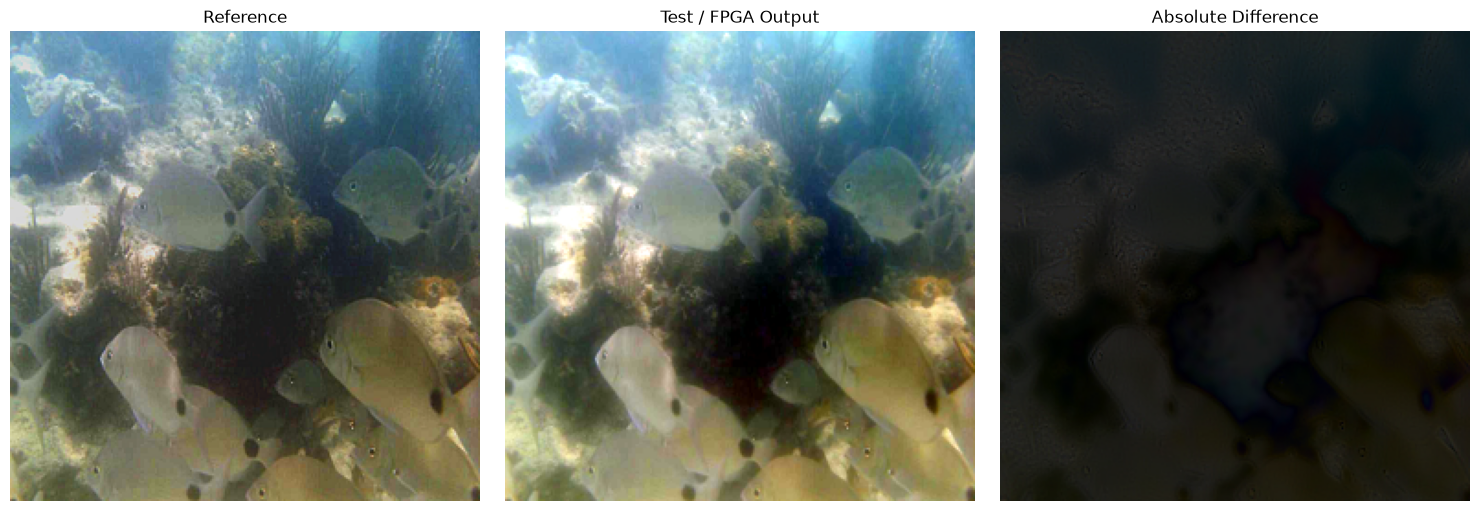

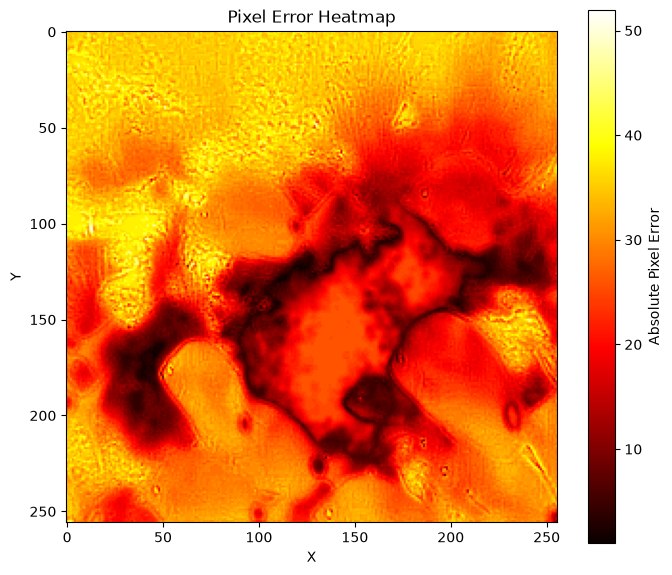

In [16]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. READ IMAGES
# ============================================================

reference_path = "./Output/output.png"
test_path = "./Output/white_balance.png"

ref = np.array(Image.open(reference_path).convert("RGB")).astype(np.int16)
test = np.array(Image.open(test_path).convert("RGB")).astype(np.int16)

# ============================================================
# 2. CHECK IMAGE SIZE
# ============================================================

if ref.shape != test.shape:
    raise ValueError(
        f"Image sizes are different!\n"
        f"Reference: {ref.shape}\n"
        f"Test:      {test.shape}"
    )

print(f"Image size: {ref.shape[1]} x {ref.shape[0]}")

# ============================================================
# 3. PIXEL DIFFERENCE
# ============================================================

# Signed error
error = test - ref

# Absolute error
abs_error = np.abs(error)

# ============================================================
# 4. ERROR STATISTICS
# ============================================================

# Maximum error among all channels/pixels
max_error = np.max(abs_error)

# Mean Absolute Error
mae = np.mean(abs_error)

# Mean Squared Error
mse = np.mean(error ** 2)

# Root Mean Squared Error
rmse = np.sqrt(mse)

# Number of pixels where ANY RGB channel differs
different_pixels = np.any(abs_error != 0, axis=2)

num_different_pixels = np.sum(different_pixels)

total_pixels = ref.shape[0] * ref.shape[1]

percentage_different = (
    num_different_pixels / total_pixels * 100
)

# ============================================================
# 5. PSNR
# ============================================================

MAX_PIXEL = 255

if mse == 0:
    psnr = float("inf")
else:
    psnr = 10 * np.log10((MAX_PIXEL ** 2) / mse)

# ============================================================
# 6. PRINT RESULTS
# ============================================================

print("\n========== IMAGE COMPARISON ==========")

print(f"Total pixels           : {total_pixels}")

print(f"Different pixels       : {num_different_pixels}")

print(f"Pixels different (%)   : {percentage_different:.6f}%")

print(f"Maximum pixel error    : {max_error}")

print(f"Mean Absolute Error    : {mae:.6f}")

print(f"Mean Squared Error     : {mse:.6f}")

print(f"RMSE                   : {rmse:.6f}")

if np.isinf(psnr):
    print("PSNR                   : INF (images are identical)")
else:
    print(f"PSNR                   : {psnr:.6f} dB")

# ============================================================
# 7. CREATE DIFFERENCE IMAGE
# ============================================================

# Scale error to 0-255 so that small differences are visible
diff_image = np.clip(abs_error, 0, 255).astype(np.uint8)

# Save difference image
Image.fromarray(diff_image).save("difference.png")

# ============================================================
# 8. FIND WORST PIXEL
# ============================================================

# Maximum error at each pixel across RGB channels
pixel_error = np.max(abs_error, axis=2)

worst_index = np.unravel_index(
    np.argmax(pixel_error),
    pixel_error.shape
)

y, x = worst_index

print("\n========== WORST PIXEL ==========")

print(f"Coordinates             : ({x}, {y})")

print(f"Reference RGB           : {ref[y, x]}")

print(f"Test RGB                : {test[y, x]}")

print(f"Absolute error          : {abs_error[y, x]}")

# ============================================================
# 9. DISPLAY IMAGES
# ============================================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(ref)
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(test)
plt.title("Test / FPGA Output")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(diff_image)
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()
plt.figure(figsize=(7, 6))

plt.imshow(pixel_error, cmap="hot")
plt.colorbar(label="Absolute Pixel Error")
plt.title("Pixel Error Heatmap")
plt.xlabel("X")
plt.ylabel("Y")

plt.tight_layout()
plt.savefig("error_heatmap.png", dpi=200)
plt.show()